In [2]:
pip install pandas

     ---------------------------------------- 9.9/9.9 MB 2.5 MB/s eta 0:00:00
     -------------------------------------- 347.5/347.5 kB 2.4 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip available: 22.3.1 -> 26.2.1
[notice] To update, run: C:\Users\hp\AppData\Local\Programs\Python\Python311\python.exe -m pip install --upgrade pip


In [3]:
pip install pandas matplotlib seaborn

     -------------------------------------- 294.9/294.9 kB 2.3 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip available: 22.3.1 -> 26.2.1
[notice] To update, run: C:\Users\hp\AppData\Local\Programs\Python\Python311\python.exe -m pip install --upgrade pip


First 5 records:
      price  area  bedrooms  bathrooms  stories mainroad guestroom basement  \
0  13300000  7420         4          2        3      yes        no       no   
1  12250000  8960         4          4        4      yes        no       no   
2  12250000  9960         3          2        2      yes        no      yes   
3  12215000  7500         4          2        2      yes        no      yes   
4  11410000  7420         4          1        2      yes       yes      yes   

  hotwaterheating airconditioning  parking prefarea furnishingstatus  
0              no             yes        2      yes        furnished  
1              no             yes        3       no        furnished  
2              no              no        2      yes   semi-furnished  
3              no             yes        3      yes        furnished  
4              no             yes        2       no        furnished  

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 545 entries, 0 to 544

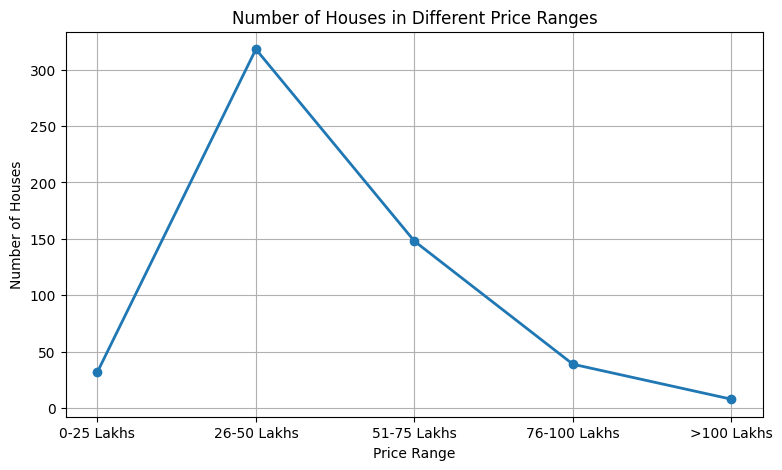


Average price of AC and Non-AC houses:
airconditioning
no     4.191940e+06
yes    6.013221e+06
Name: price, dtype: float64


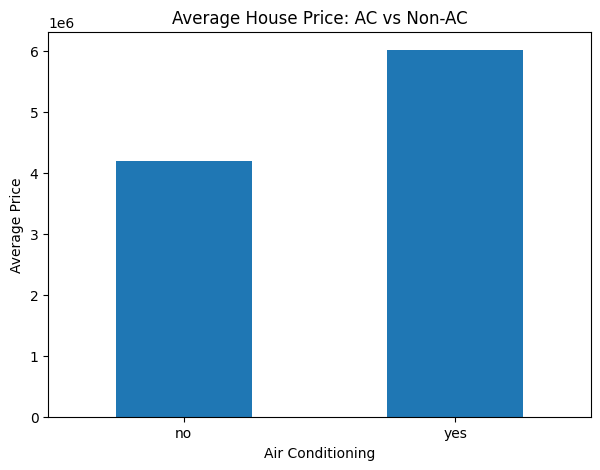


Average house price according to parking:
parking
0    4.136017e+06
1    5.190389e+06
2    5.896328e+06
3    5.867167e+06
Name: price, dtype: float64


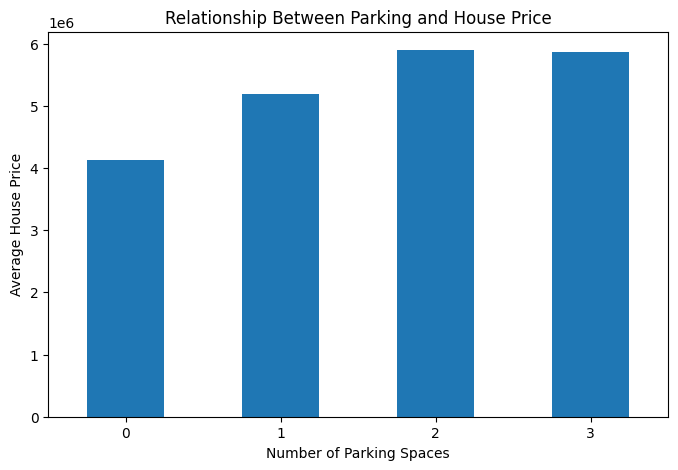


Average price: <5000 sqft and No Prefarea:
3827671.56133829

Average price: >5000 sqft and Prefarea:
6546807.692307692

Price Gap:
2719136.130969402


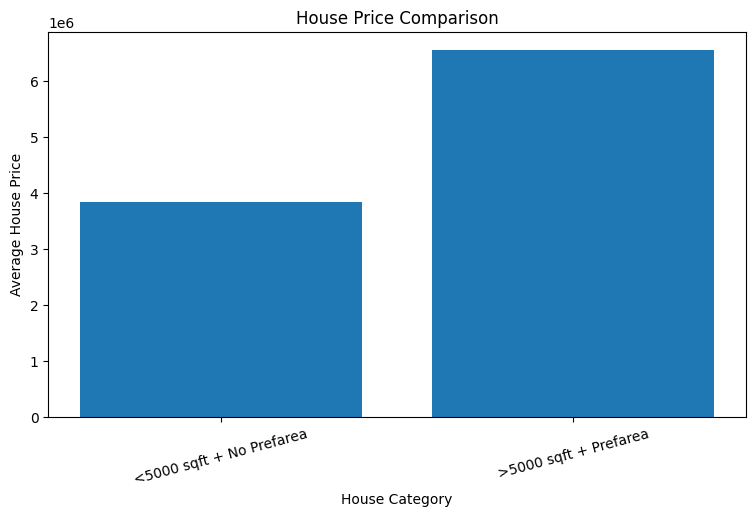

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# --------------------------------------------------
# LOAD DATA
# --------------------------------------------------

df = pd.read_csv("Housing.csv")

print("First 5 records:")
print(df.head())

print("\nDataset Information:")
print(df.info())

# --------------------------------------------------
# QUESTION 1
# Houses in different price ranges
# --------------------------------------------------

bins = [0, 2500000, 5000000, 7500000, 10000000, float("inf")]

labels = [
    "0-25 Lakhs",
    "26-50 Lakhs",
    "51-75 Lakhs",
    "76-100 Lakhs",
    ">100 Lakhs"
]

df["price_range"] = pd.cut(
    df["price"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

price_count = df["price_range"].value_counts().sort_index()

print("\nNumber of houses in each price range:")
print(price_count)

# Line chart
plt.figure(figsize=(9, 5))

plt.plot(
    price_count.index,
    price_count.values,
    marker="o",
    linewidth=2
)

plt.title("Number of Houses in Different Price Ranges")
plt.xlabel("Price Range")
plt.ylabel("Number of Houses")
plt.grid(True)

plt.show()


# --------------------------------------------------
# QUESTION 2
# Average house price for AC and Non-AC houses
# --------------------------------------------------

average_ac_price = df.groupby(
    "airconditioning"
)["price"].mean()

print("\nAverage price of AC and Non-AC houses:")
print(average_ac_price)

# Bar chart
plt.figure(figsize=(7, 5))

average_ac_price.plot(kind="bar")

plt.title("Average House Price: AC vs Non-AC")
plt.xlabel("Air Conditioning")
plt.ylabel("Average Price")
plt.xticks(rotation=0)

plt.show()


# --------------------------------------------------
# QUESTION 3
# Relationship between parking and house price
# --------------------------------------------------

parking_price = df.groupby("parking")["price"].mean()

print("\nAverage house price according to parking:")
print(parking_price)

# Bar chart
plt.figure(figsize=(8, 5))

parking_price.plot(kind="bar")

plt.title("Relationship Between Parking and House Price")
plt.xlabel("Number of Parking Spaces")
plt.ylabel("Average House Price")
plt.xticks(rotation=0)

plt.show()


# --------------------------------------------------
# QUESTION 4
# Price gap based on area and preferred area
# --------------------------------------------------

group1 = df[
    (df["area"] < 5000) &
    (df["prefarea"] == "no")
]

group2 = df[
    (df["area"] > 5000) &
    (df["prefarea"] == "yes")
]

average_group1 = group1["price"].mean()
average_group2 = group2["price"].mean()

price_gap = abs(average_group2 - average_group1)

print("\nAverage price: <5000 sqft and No Prefarea:")
print(average_group1)

print("\nAverage price: >5000 sqft and Prefarea:")
print(average_group2)

print("\nPrice Gap:")
print(price_gap)


# Comparison chart
groups = [
    "<5000 sqft + No Prefarea",
    ">5000 sqft + Prefarea"
]

prices = [
    average_group1,
    average_group2
]

plt.figure(figsize=(9, 5))

plt.bar(groups, prices)

plt.title("House Price Comparison")
plt.xlabel("House Category")
plt.ylabel("Average House Price")

plt.xticks(rotation=15)

plt.show()



Number of houses in each price range:
price_range
0-25 Lakhs       32
26-50 Lakhs     318
51-75 Lakhs     148
76-100 Lakhs     39
>100 Lakhs        8
Name: count, dtype: int64


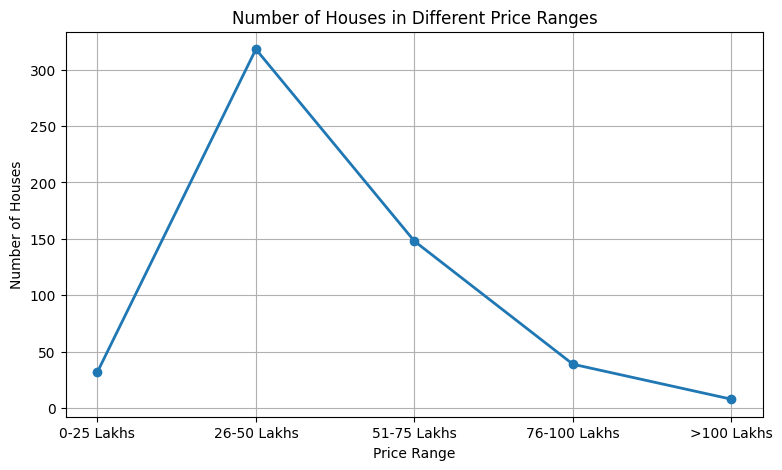

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
#

bins = [0, 2500000, 5000000, 7500000, 10000000, float("inf")]

labels = [
    "0-25 Lakhs",
    "26-50 Lakhs",
    "51-75 Lakhs",
    "76-100 Lakhs",
    ">100 Lakhs"
]

df["price_range"] = pd.cut(
    df["price"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

price_count = df["price_range"].value_counts().sort_index()

print("\nNumber of houses in each price range:")
print(price_count)

# Line chart
plt.figure(figsize=(9, 5))

plt.plot(
    price_count.index,
    price_count.values,
    marker="o",
    linewidth=2
)
plt.title("Number of Houses in Different Price Ranges")
plt.xlabel("Price Range")
plt.ylabel("Number of Houses")
plt.grid(True)

plt.show()


Average price of AC and Non-AC houses:
airconditioning
no     4.191940e+06
yes    6.013221e+06
Name: price, dtype: float64


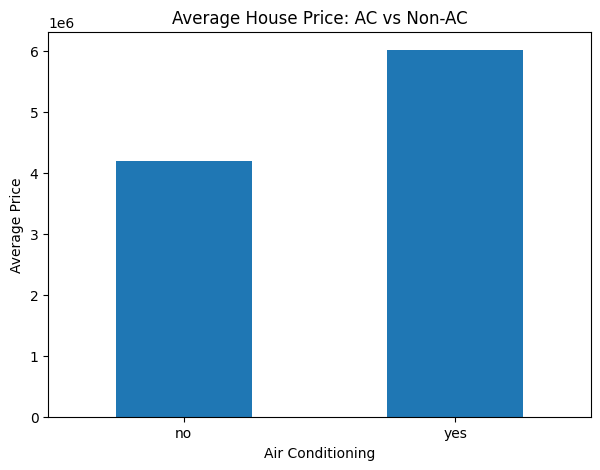

In [6]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("Housing.csv")

bins = [0, 2500000, 5000000, 7500000, 10000000, float("inf")]

labels = [
    "0-25 Lakhs",
    "26-50 Lakhs",
    "51-75 Lakhs",
    "76-100 Lakhs",
    ">100 Lakhs"
]

df["price_range"] = pd.cut(
    df["price"],
    bins=bins,
    labels=labels,
    include_lowest=True
)



average_ac_price = df.groupby(
    "airconditioning"
)["price"].mean()

print("\nAverage price of AC and Non-AC houses:")
print(average_ac_price)

# Bar chart
plt.figure(figsize=(7, 5))

average_ac_price.plot(kind="bar")

plt.title("Average House Price: AC vs Non-AC")
plt.xlabel("Air Conditioning")
plt.ylabel("Average Price")
plt.xticks(rotation=0)

plt.show()



Average house price according to parking:
parking
0    4.136017e+06
1    5.190389e+06
2    5.896328e+06
3    5.867167e+06
Name: price, dtype: float64


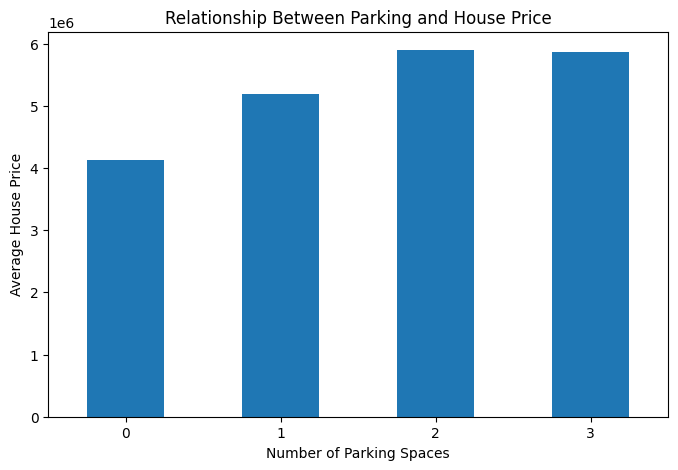

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("Housing.csv")

bins = [0, 2500000, 5000000, 7500000, 10000000, float("inf")]

labels = [
    "0-25 Lakhs",
    "26-50 Lakhs",
    "51-75 Lakhs",
    "76-100 Lakhs",
    ">100 Lakhs"
]

df["price_range"] = pd.cut(
    df["price"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

parking_price = df.groupby("parking")["price"].mean()

print("\nAverage house price according to parking:")
print(parking_price)

# Bar chart
plt.figure(figsize=(8, 5))

parking_price.plot(kind="bar")

plt.title("Relationship Between Parking and House Price")
plt.xlabel("Number of Parking Spaces")
plt.ylabel("Average House Price")
plt.xticks(rotation=0)

plt.show()


Average price: <5000 sqft and No Prefarea:
3827671.56133829

Average price: >5000 sqft and Prefarea:
6546807.692307692

Price Gap:
2719136.130969402


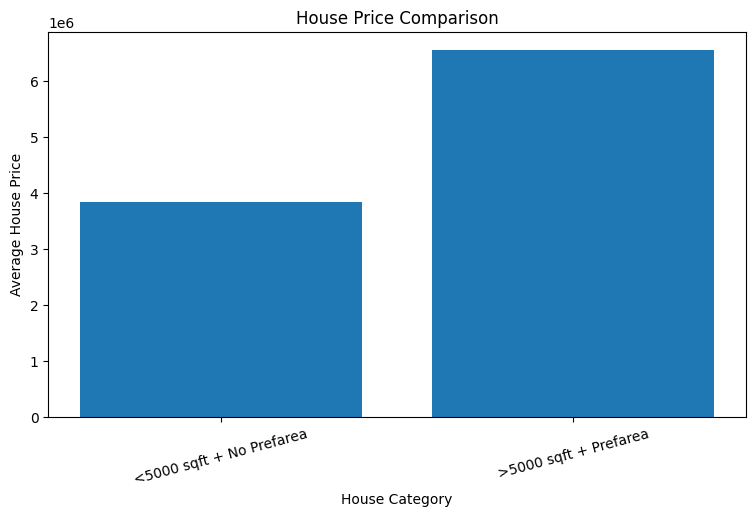

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("Housing.csv")

bins = [0, 2500000, 5000000, 7500000, 10000000, float("inf")]

labels = [
    "0-25 Lakhs",
    "26-50 Lakhs",
    "51-75 Lakhs",
    "76-100 Lakhs",
    ">100 Lakhs"
]

df["price_range"] = pd.cut(
    df["price"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

group1 = df[
    (df["area"] < 5000) &
    (df["prefarea"] == "no")
]

group2 = df[
    (df["area"] > 5000) &
    (df["prefarea"] == "yes")
]

average_group1 = group1["price"].mean()
average_group2 = group2["price"].mean()

price_gap = abs(average_group2 - average_group1)

print("\nAverage price: <5000 sqft and No Prefarea:")
print(average_group1)

print("\nAverage price: >5000 sqft and Prefarea:")
print(average_group2)

print("\nPrice Gap:")
print(price_gap)


# Comparison chart
groups = [
    "<5000 sqft + No Prefarea",
    ">5000 sqft + Prefarea"
]

prices = [
    average_group1,
    average_group2
]

plt.figure(figsize=(9, 5))

plt.bar(groups, prices)

plt.title("House Price Comparison")
plt.xlabel("House Category")
plt.ylabel("Average House Price")

plt.xticks(rotation=15)

plt.show()
